#### All Global Imports

In [39]:
import pandas as pd

### Load the data set

In [40]:
# url = "https://raw.githubusercontent.com/fivethirtyeight/data/master/alcohol-consumption/drinks.csv"
# df = pd.read_csv(url)
df = pd.read_csv("../assets/drinks.csv")
print(df.head())

       country  beer_servings  spirit_servings  wine_servings  \
0  Afghanistan              0                0              0   
1      Albania             89              132             54   
2      Algeria             25                0             14   
3      Andorra            245              138            312   
4       Angola           -217               57             45   

   total_litres_of_pure_alcohol continent  
0                           0.0      Asia  
1                           4.9    Europe  
2                           0.7    Africa  
3                          12.4    Europe  
4                           5.9    Africa  


#### Initial Inspection (Get the shape)

In [41]:
print("Total rows (Countries) ", df.shape[0])
print("Total columns (Features) ", df.shape[1])

Total rows (Countries)  193
Total columns (Features)  6


### Schema Health Checking
#### The Goal: Ensure every column has the correct data type.
- Check df.info() to see if numbers are stored correctly.

- Idea: Look at columns like beer_servings, spirit_servings, wine_servings, and total_litres_of_pure_alcohol. Are they stored as floats/integers, or did any accidental text strings slip in?

In [42]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   country                       193 non-null    object 
 1   beer_servings                 193 non-null    int64  
 2   spirit_servings               193 non-null    int64  
 3   wine_servings                 193 non-null    int64  
 4   total_litres_of_pure_alcohol  193 non-null    float64
 5   continent                     192 non-null    object 
dtypes: float64(1), int64(3), object(2)
memory usage: 9.2+ KB
None


#### Spotting Missing Values & Imputation
- The Goal: Handle missing data gracefully.
- Idea: If a continent is missing for a country, can you write a simple rule or imputation step to fill it based on the country name?

In [43]:
missing_values = df.isnull().sum()
print(missing_values)

country                         0
beer_servings                   0
spirit_servings                 0
wine_servings                   0
total_litres_of_pure_alcohol    0
continent                       1
dtype: int64


####  DATA SANITIZATION

In [44]:
df['continent'] = df['continent'].fillna('Unknown')


In [45]:

# print(df[df['country'] == 'Sweden']) # boolean indexing
# print(df.query("country == 'Sweden'")[['country','continent']])
# print(df.loc[df['country'] == 'Sweden', ['country','continent']])
print(df[df["country"].isin(["Sweden","India"])][['country','continent']])


    country continent
77    India      Asia
165  Sweden   Unknown


#### Handling Outliers and Anomalies
- The Goal: Clean out unrealistic numbers using logical sanity checks.
- Check df.describe() to look at minimum and maximum values.
- Idea: Filter out or investigate rows where alcohol servings are negative, or where total_litres_of_pure_alcohol doesn't mathematically align with the servings.

In [46]:
print(df.describe().T[['mean','std','min','max']])

                                    mean         std    min    max
beer_servings                 103.911917  103.463900 -217.0  376.0
spirit_servings                80.994819   88.284312    0.0  438.0
wine_servings                  49.450777   79.697598    0.0  370.0
total_litres_of_pure_alcohol    4.717098    3.773298    0.0   14.4


In [51]:
print("negative beer servings rows :\n",df[df['beer_servings'] < 0][['country','beer_servings']])
beer_serving_negative_count= (df['beer_servings'] < 0).sum()
print("Beer serving negative count:",beer_serving_negative_count)

negative beer servings rows :
   country  beer_servings
4  Angola           -217
Beer serving negative count: 1


### Lets fix negative , either feed zero or filter out countries with negative serving

In [52]:
df_copy = df.copy()
print("df dimension before removing negative beer servings:", df.shape)
df = df[df['beer_servings'] >= 0]
print("df dimension after removing negative beer servings:", df.shape)

df dimension before removing negative beer servings: (193, 6)
df dimension after removing negative beer servings: (192, 6)


### string sanitization

In [56]:
# get all features names from dataframe
feature_names = df.columns
print(feature_names)
# assume Identifying leading or trailing spaces in feature name "continent"
df['continent'] = df['continent'].str.strip().str.title()
print(df['continent'].head())

Index(['country', 'beer_servings', 'spirit_servings', 'wine_servings',
       'total_litres_of_pure_alcohol', 'continent'],
      dtype='object')
0             Asia
1           Europe
2           Africa
3           Europe
5    North America
Name: continent, dtype: object


In [ ]:
print(df['continent'].unique())

['Asia' 'Europe' 'Africa' 'North America' 'South America' 'Oceania'
 'Unknown']


### Grouping and Aggregation
- The Goal: Answer business/analytical questions with simple aggregations.
- Which continent consumes the most beer on average?
- Which country has the absolute highest total_litres_of_pure_alcohol?

In [59]:
average_beer_by_continent = df.groupby('continent')['beer_servings'].mean().round(2)
print(average_beer_by_continent)

continent
Africa            58.48
Asia              37.05
Europe           194.73
North America    145.43
Oceania           89.69
South America    175.08
Unknown          152.00
Name: beer_servings, dtype: float64


In [60]:
top_drinker = df.loc[df['total_litres_of_pure_alcohol'].idxmax()]
print(top_drinker)

country                         Belarus
beer_servings                       142
spirit_servings                     373
wine_servings                        42
total_litres_of_pure_alcohol       14.4
continent                        Europe
Name: 15, dtype: object


### Summary on this notebook
- 1. Inspecting Structure (head() & info()): How to quickly check row counts, columns, and data types to catch unexpected text fields.

- 2. Finding Dirt (isnull()): Spotting missing data and learning how to handle it safely (fillna()).

- 3. Text Cleaning (str.strip()): Normalizing string categories so grouping operations don't break due to hidden trailing spaces or typos.

- 4. Sanity Checks (< 0 filters): Using simple logical conditions to ensure data falls within realistic bounds.

- 5. Summarizing & Grouping (describe() & groupby()): Turning thousands of rows into actionable answers like regional averages and extreme outliers.

---
## Enriched EDA Labs, Visualizations & Viva Preparation
The sections below provide extended exploratory visualizations, multi-condition `.loc` filtering, and interview viva concepts.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


### 4. Simple `df.loc` Queries & Anomaly Filtering
Using `df.loc[rows, columns]` for simple filtering and inspection:
- Filter specific continents
- Filter high-consumption nations
- Catch negative or invalid values (data quality audit)

In [6]:
# 1. Simple df.loc: Filter European countries and select specific columns
df_europe = df.loc[df['continent'] == 'Europe', ['country', 'beer_servings', 'wine_servings']].head(5)
print('Top 5 European countries (.loc):')
display(df_europe)

# 2. Simple df.loc: Filter countries with total pure alcohol > 10 litres
heavy_drinkers = df.loc[df['total_litres_of_pure_alcohol'] > 10, ['country', 'continent', 'total_litres_of_pure_alcohol']]
print(f'\nCountries with pure alcohol > 10L ({len(heavy_drinkers)} countries):')
display(heavy_drinkers.head())

# 3. Simple df.loc: Data Audit — detect any invalid negative beer servings
negative_beer = df.loc[df['beer_servings'] < 0, ['country', 'beer_servings', 'continent']]
print('\nData Quality Audit: Countries with negative beer servings:')
display(negative_beer)

# 4. Simple df.loc: Multi-condition filter (Asia and beer_servings > 100)
asia_beer = df.loc[(df['continent'] == 'Asia') & (df['beer_servings'] > 100), ['country', 'beer_servings']]
print('\nAsian countries with beer servings > 100:')
display(asia_beer)

Top 5 European countries (.loc):


,country,beer_servings,wine_servings
1,Albania,89,54
3,Andorra,245,312
7,Armenia,21,11
9,Austria,279,191
10,Azerbaijan,21,5



Countries with pure alcohol > 10L (25 countries):


,country,continent,total_litres_of_pure_alcohol
3,Andorra,Europe,12.4
8,Australia,Oceania,10.4
15,Belarus,Europe,14.4
16,Belgium,Europe,10.5
25,Bulgaria,Europe,10.3



Data Quality Audit: Countries with negative beer servings:


,country,beer_servings,continent
4,Angola,-217,Africa



Asian countries with beer servings > 100:


,country,beer_servings
87,Kazakhstan,124
138,South Korea,140
141,Russian Federation,247
189,Vietnam,111


### 5. Simple Visualizations

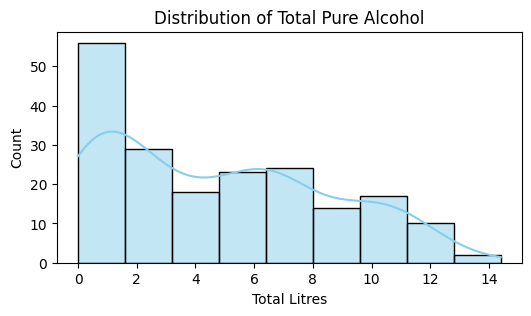

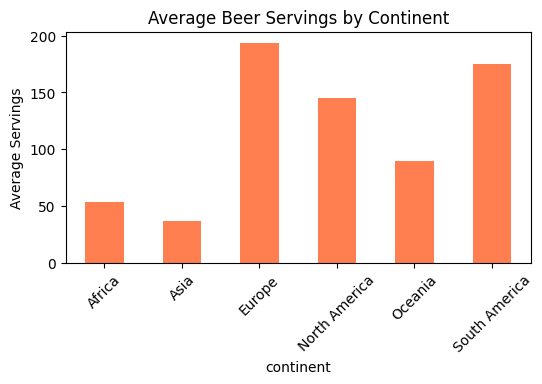

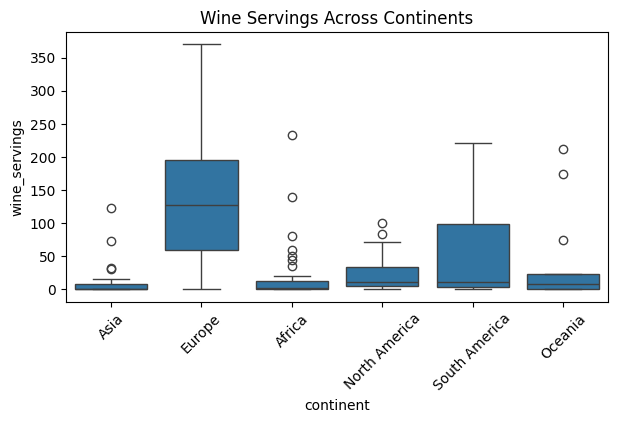

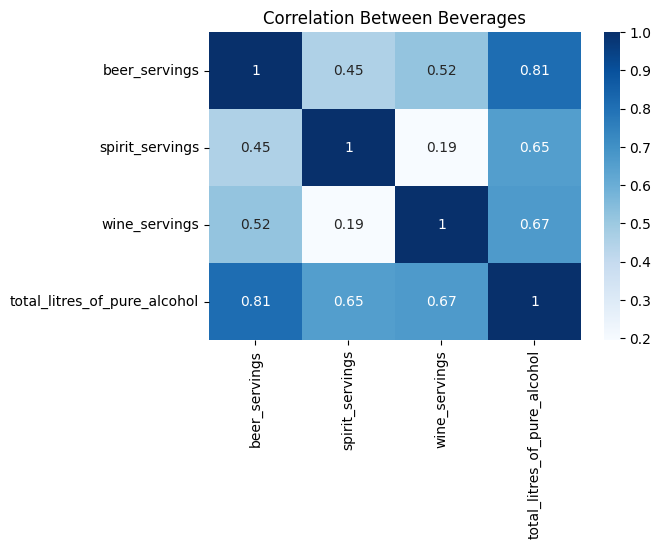

In [7]:
# 1. Distribution of Total Alcohol
plt.figure(figsize=(6, 3))
sns.histplot(df['total_litres_of_pure_alcohol'], kde=True, color='skyblue')
plt.title('Distribution of Total Pure Alcohol')
plt.xlabel('Total Litres')
plt.show()

# 2. Average Beer Servings by Continent (Bar Plot)
plt.figure(figsize=(6, 3))
average_beer_by_continent.plot(kind='bar', color='coral')
plt.title('Average Beer Servings by Continent')
plt.ylabel('Average Servings')
plt.xticks(rotation=45)
plt.show()

# 3. Wine Servings Distribution by Continent (Boxplot)
plt.figure(figsize=(7, 3.5))
sns.boxplot(x='continent', y='wine_servings', data=df)
plt.title('Wine Servings Across Continents')
plt.xticks(rotation=45)
plt.show()

# 4. Correlation Heatmap
plt.figure(figsize=(6, 4))
num_cols = ['beer_servings', 'spirit_servings', 'wine_servings', 'total_litres_of_pure_alcohol']
sns.heatmap(df[num_cols].corr(), annot=True, cmap='Blues')
plt.title('Correlation Between Beverages')
plt.show()

### 6. Alcohol Consumption: All Key Findings & Extreme Values
Summary of the highest and lowest consumers for each beverage type using `.loc` and `.idxmax()` / `.idxmin()`.

In [8]:
# Top consumer for each category using .loc & .idxmax()
top_beer = df.loc[df['beer_servings'].idxmax(), ['country', 'beer_servings', 'continent']].to_dict()
top_spirit = df.loc[df['spirit_servings'].idxmax(), ['country', 'spirit_servings', 'continent']].to_dict()
top_wine = df.loc[df['wine_servings'].idxmax(), ['country', 'wine_servings', 'continent']].to_dict()
top_alcohol = df.loc[df['total_litres_of_pure_alcohol'].idxmax(), ['country', 'total_litres_of_pure_alcohol', 'continent']].to_dict()

# Zero alcohol consumption countries using .loc
zero_alcohol_countries = df.loc[df['total_litres_of_pure_alcohol'] == 0, 'country'].tolist()

findings_df = pd.DataFrame([
    {'Category': 'Beer Leader', 'Country': top_beer['country'], 'Value': f"{top_beer['beer_servings']} servings", 'Continent': top_beer['continent']},
    {'Category': 'Spirit Leader', 'Country': top_spirit['country'], 'Value': f"{top_spirit['spirit_servings']} servings", 'Continent': top_spirit['continent']},
    {'Category': 'Wine Leader', 'Country': top_wine['country'], 'Value': f"{top_wine['wine_servings']} servings", 'Continent': top_wine['continent']},
    {'Category': 'Total Alcohol Leader', 'Country': top_alcohol['country'], 'Value': f"{top_alcohol['total_litres_of_pure_alcohol']} L", 'Continent': top_alcohol['continent']}
])

print('--- Global Consumption Leaders ---')
display(findings_df)

print(f'\nCountries with 0.0 Litres alcohol consumption ({len(zero_alcohol_countries)} countries):')
print(', '.join(zero_alcohol_countries))

--- Global Consumption Leaders ---


,Category,Country,Value,Continent
0,Beer Leader,Namibia,376 servings,Africa
1,Spirit Leader,Grenada,438 servings,North America
2,Wine Leader,France,370 servings,Europe
3,Total Alcohol Leader,Belarus,14.4 L,Europe



Countries with 0.0 Litres alcohol consumption (13 countries):
Afghanistan, Bangladesh, North Korea, Iran, Kuwait, Libya, Maldives, Marshall Islands, Mauritania, Monaco, Pakistan, San Marino, Somalia


---
### 7. 💡 Pro Pandas Tricks: Mean, Min, Max & Std
Essential shortcuts for statistical exploration and interview preparation.

In [9]:
# Trick 1: idxmax() & idxmin() — Find country with Min or Max WITHOUT sorting
max_wine_idx = df['wine_servings'].idxmax()
min_wine_idx = df['wine_servings'].idxmin()

print('Highest Wine Consumer (.loc + idxmax):', df.loc[max_wine_idx, ['country', 'wine_servings', 'continent']].to_dict())
print('Lowest Wine Consumer  (.loc + idxmin):', df.loc[min_wine_idx, ['country', 'wine_servings', 'continent']].to_dict())

# Trick 2: Multi-Aggregation with .agg() — Mean, Std, Min, Max in ONE call
stats_table = df.groupby('continent')['total_litres_of_pure_alcohol'].agg(
    Count='count',
    Mean='mean',
    Std='std',
    Min='min',
    Median='median',
    Max='max'
).round(2)
display(stats_table)

# Trick 3: The Pandas vs NumPy Standard Deviation Trap (ddof=1 vs ddof=0)
pandas_sample_std = df['beer_servings'].std()       # ddof=1 (Sample standard deviation, N-1)
numpy_pop_std     = df['beer_servings'].std(ddof=0) # ddof=0 (Population standard deviation, N)

print(f'Pandas Default (Sample, ddof=1):     {pandas_sample_std:.4f}')
print(f'NumPy Default  (Population, ddof=0): {numpy_pop_std:.4f}')
print(f'Difference:                          {pandas_sample_std - numpy_pop_std:.4f}')

# Trick 4: Coefficient of Variation (CV = std / mean) — Relative spread across columns
cv_metrics = (df[['beer_servings', 'spirit_servings', 'wine_servings', 'total_litres_of_pure_alcohol']].std() / 
              df[['beer_servings', 'spirit_servings', 'wine_servings', 'total_litres_of_pure_alcohol']].mean() * 100)
print('\nCoefficient of Variation (%):')
print(cv_metrics.round(2))

Highest Wine Consumer (.loc + idxmax): {'country': 'France', 'wine_servings': 370, 'continent': 'Europe'}
Lowest Wine Consumer  (.loc + idxmin): {'country': 'Afghanistan', 'wine_servings': 0, 'continent': 'Asia'}


,Count,Mean,Std,Min,Median,Max
continent,,,,,,
Africa,53,3.01,2.65,0.0,2.30,9.1
Asia,44,2.17,2.77,0.0,1.20,11.5
Europe,45,8.62,3.36,0.0,10.00,14.4
North America,23,6.00,2.41,2.2,6.30,11.9
Oceania,16,3.38,3.35,0.0,1.75,10.4
South America,12,6.31,1.53,3.8,6.85,8.3


Pandas Default (Sample, ddof=1):     103.4639
NumPy Default  (Population, ddof=0): 103.1955
Difference:                          0.2684

Coefficient of Variation (%):
beer_servings                    99.57
spirit_servings                 109.00
wine_servings                   161.17
total_litres_of_pure_alcohol     79.99
dtype: float64


---
### 8. 🎯 Critical Interview Questions & Viva Hacks (Mean, Min, Max, Std)

#### Q1: Why does Pandas `.std()` give a different value than NumPy `np.std()`?
- **Answer:** **Bessel's Correction ($N - 1$).**  
  - Pandas computes **Sample Standard Deviation** by default with degrees of freedom `ddof=1` (dividing by $N - 1$) to remove downward bias in estimating population variance from a sample.
  - NumPy computes **Population Standard Deviation** with `ddof=0` (dividing by $N$).
  - *Viva tip:* Always clarify whether `ddof=1` or `ddof=0` is required when discussing variance!

---

#### Q2: If every country's beer servings are increased by a constant $+10$, what happens to Mean, Min, Max, and Std?
- **Answer:**
  - $\text{Mean}_{\text{new}} = \text{Mean} + 10$
  - $\text{Min}_{\text{new}} = \text{Min} + 10$
  - $\text{Max}_{\text{new}} = \text{Max} + 10$
  - $\mathbf{\text{Std}_{\text{new}} = \text{Std}}$ **(UNCHANGED!)**
  - *Why?* Adding a constant shifts the distribution along the axis, but the **distances between data points and the mean remain identical**. Spread/dispersion does not change.

---

#### Q3: What happens if every value is multiplied by a positive constant $c$ (e.g., unit conversion)?
- **Answer:**
  - $\text{Mean}_{\text{new}} = c \times \text{Mean}$
  - $\text{Min}_{\text{new}} = c \times \text{Min}$
  - $\text{Max}_{\text{new}} = c \times \text{Max}$
  - $\mathbf{\text{Std}_{\text{new}} = |c| \times \text{Std}}$  
  - *Variance* scales by $c^2$ (e.g., doubling values quadruples variance).

---

#### Q4: When should you report Median & IQR instead of Mean & Std?
- **Answer:**
  - When data is **heavily skewed** or contains **extreme outliers** (like `wine_servings` where global mean is $49.4$ but median is $9.0$, and France has $370$ servings).
  - Mean is sensitive to extreme values; **Median is robust (50% breakdown point)**.
  - Standard deviation is inflated by squared differences; **IQR ($Q_3 - Q_1$) is resistant to outliers**.

---

#### Q5: What is the 68–95–99.7 Empirical Rule?
- **Answer:** For a **bell-shaped (Gaussian/Normal)** distribution:
  - $\approx 68.27\%$ of values fall within $\mu \pm 1\sigma$
  - $\approx 95.45\%$ of values fall within $\mu \pm 2\sigma$
  - $\approx 99.73\%$ of values fall within $\mu \pm 3\sigma$
  - Points beyond $\pm 3\sigma$ are flagged as statistical outliers (Z-score $> 3$).